In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ast

In [2]:
cm_df = pd.read_csv('college_med_retrospect_experiment_anlysis.csv')
cm_correctness = cm_df["exp_correctness_record"].to_numpy()
cm_correctness = np.array([ast.literal_eval(s) for s in cm_correctness])

In [3]:
hb_df = pd.read_csv('hs_bio_retrospect_experiment_anlysis.csv')
hb_correctness = hb_df["exp_correctness_record"].to_numpy()
hb_correctness = np.array([ast.literal_eval(s) for s in hb_correctness])

In [4]:
hg_df = pd.read_csv('hs_geo_retrospect_experiment_anlysis.csv')
hg_correctness = hg_df["exp_correctness_record"].to_numpy()
hg_correctness = np.array([ast.literal_eval(s) for s in hg_correctness])

In [5]:
sciq_df = pd.read_csv('sciq_retrospect_experiment_anlysis.csv')
sciq_correctness = sciq_df["exp_correctness_record"].to_numpy()[:1000]
sciq_correctness = np.array([ast.literal_eval(s) for s in sciq_correctness])

In [17]:
# produce the avg score, total length 10
def get_avg(correctness):
    row_count, col_count = correctness.shape
    avg_correctness = []
    for i in range(col_count):
        cur = correctness[:, i]
        avg_correctness.append(float(sum(cur) / row_count) * 10)
    assert len(avg_correctness) == 10
    return avg_correctness

In [18]:
cm_avg = get_avg(cm_correctness)
hb_avg = get_avg(hb_correctness)
hg_avg = get_avg(hg_correctness)
sciq_avg = get_avg(sciq_correctness)

In [19]:
print(cm_avg)
print(hb_avg)
print(hg_avg)
print(sciq_avg)

[40.8, 62.5, 67.75, 69.75, 71.39999999999999, 72.64999999999999, 72.4, 73.7, 74.3, 73.60000000000001]
[52.50720461095101, 67.69452449567724, 71.95965417867436, 75.4178674351585, 76.13832853025937, 77.63688760806916, 77.57925072046109, 77.69452449567724, 78.27089337175792, 78.2420749279539]
[51.2, 73.37777777777778, 79.42222222222222, 80.57777777777778, 81.77777777777777, 81.51111111111112, 82.71111111111111, 83.77777777777779, 84.0, 84.48888888888888]
[77.12, 88.13000000000001, 90.41, 90.91, 91.25, 91.75, 91.96, 92.33000000000001, 92.56, 92.57999999999998]


<function matplotlib.pyplot.show(close=None, block=None)>

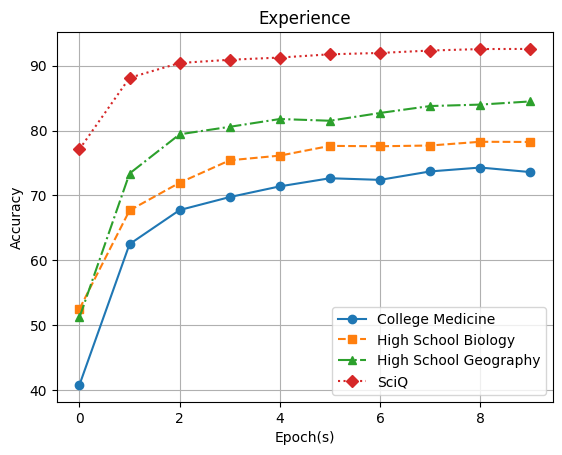

In [20]:
plt.title("Experience")
plt.xlabel("Epoch(s)")
plt.ylabel("Accuracy")
plt.plot(cm_avg, marker='o', linestyle='-', label='College Medicine')
plt.plot(hb_avg, marker='s', linestyle='--', label='High School Biology')
plt.plot(hg_avg, marker='^', linestyle='-.', label='High School Geography')
plt.plot(sciq_avg, marker='D', linestyle=':', label='SciQ')
plt.legend()
plt.grid()
plt.show